# Dados e preparação

**Dados** são registros de fatos, observações ou medidas. Eles podem ser números, textos, datas, imagens ou outras formas de registro. Em uma tabela, cada **linha** costuma representar uma observação e cada **coluna**, uma característica dessa observação. Neste notebook, por exemplo, as linhas representam veículos e colunas como `ENGINESIZE`, `FUELTYPE` e `CO2EMISSIONS` descrevem características de cada veículo.

Um dado isolado nem sempre responde a uma pergunta. O contexto explica o que foi medido, em que unidade, em qual período e como interpretar cada valor. A **Ciência de Dados** reúne métodos para preparar e analisar dados e comunicar resultados que ajudem a responder perguntas ou apoiar decisões.

## O fluxo ETL

ETL é a sigla de **Extract, Transform, Load**:

1. **Extract (extrair):** obter dados de uma fonte, como arquivo CSV, planilha, banco de dados ou API.
2. **Transform (transformar):** verificar e preparar os dados. Isso pode incluir corrigir tipos, tratar ausências, padronizar categorias e combinar tabelas.
3. **Load (carregar):** guardar os dados preparados em um destino, como um banco de dados, data warehouse ou DataFrame para análise.

A leitura do CSV na próxima célula extrai os dados do arquivo e os carrega no DataFrame `df`, uma estrutura tabular do pandas. As células seguintes fazem algumas transformações. Este exemplo usa um único arquivo; portanto, não demonstra a combinação de várias tabelas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../datasets/FuelConsumptionCo2.csv');
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-null   str    
 2   MODEL                     1067 non-null   str    
 3   VEHICLECLASS              1067 non-null   str    
 4   ENGINESIZE                1067 non-null   float64
 5   CYLINDERS                 1067 non-null   int64  
 6   TRANSMISSION              1067 non-null   str    
 7   FUELTYPE                  1067 non-null   str    
 8   FUELCONSUMPTION_CITY      1067 non-null   float64
 9   FUELCONSUMPTION_HWY       1067 non-null   float64
 10  FUELCONSUMPTION_COMB      1067 non-null   float64
 11  FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 12  CO2EMISSIONS              1067 non-null   int64  
dtypes: float64(4), int64(4), str(5)
memory usage: 108.5 KB


### Verificação e limpeza dos dados

Antes de calcular estatísticas ou treinar um modelo, precisamos entender a qualidade do conjunto de dados. A chamada `df.info()` acima mostra o número de linhas, os nomes das colunas, os tipos de dados e quantos valores não nulos há em cada coluna. Para contar ausências por coluna, também podemos usar `df.isna().sum()`.

Em pandas, valores ausentes podem aparecer como `NaN`, `None` ou `NaT` (para datas). `isna()` localiza esses valores. `fillna()` permite substituí-los e `dropna()` remove linhas ou colunas que os contêm. A escolha depende do motivo da ausência e da pergunta da análise: preencher pela média, por exemplo, pode fazer sentido em alguns casos numéricos, mas não em todos; remover linhas também pode descartar informação importante.

Confira ainda se os tipos fazem sentido. Uma coluna numérica importada como texto pode conter espaços, símbolos ou marcas como `N/A`. Depois de investigar e corrigir os valores, uma conversão como `pd.to_numeric()` pode ser apropriada. Colunas categóricas, como o tipo de combustível, representam grupos; muitos modelos precisam que essas categorias sejam codificadas em uma forma numérica antes do treinamento.

A limpeza não significa apagar tudo o que parece incomum. Primeiro investigamos os valores e decidimos se são erros, casos válidos ou algo que exige uma estratégia específica.


In [4]:
df['FUELTYPE'].unique()

<StringArray>
['Z', 'D', 'X', 'E']
Length: 4, dtype: str

In [5]:
df['FUELTYPE'] = df['FUELTYPE'].replace({'Z':'Gasoline', 'D':'Diesel', 'E':'Ethanol', 'X':'Electricity'})
df['NUMERICFUELTYPE'] = df['FUELTYPE'].replace({'Gasoline':0, 'Diesel':1, 'Ethanol':2, 'Electricity':3})   
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS,NUMERICFUELTYPE
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Gasoline,9.9,6.7,8.5,33,196,0
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Gasoline,11.2,7.7,9.6,29,221,0
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Gasoline,6.0,5.8,5.9,48,136,0
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Gasoline,12.7,9.1,11.1,25,255,0
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Gasoline,12.1,8.7,10.6,27,244,0


# Feature Engineering

**Feature engineering** (engenharia de atributos) é o processo de criar, transformar ou selecionar colunas que representem melhor o problema. Uma *feature* é uma característica usada na análise ou como entrada de um modelo.

Nas células seguintes, o tipo de combustível é convertido de códigos curtos para nomes mais legíveis e também é criada uma coluna numérica. Depois, `FUELCLASSIFICATION` resume três medidas de consumo em uma média e aplica faixas definidas no próprio código. Essas faixas são regras didáticas: em um problema real, os limites e os nomes das classes devem ser justificados pelo contexto e documentados. Observe também que criar uma coluna numérica para categorias não significa automaticamente que ela será usada pelo modelo; é preciso escolher as colunas de entrada explicitamente.


In [6]:
df['FUELCLASSIFICATION'] = (
    df[['FUELCONSUMPTION_COMB', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY']]
      .mean(axis=1)
      .apply(lambda x: 'baixo' if x > 12 else 'medio' if 7 < x <= 12 else 'alto')
)
df['FUELCLASSIFICATION']

0       medio
1       medio
2        alto
3       medio
4       medio
        ...  
1062    medio
1063    medio
1064    medio
1065    medio
1066    baixo
Name: FUELCLASSIFICATION, Length: 1067, dtype: str

## Análise Exploratória de Dados (EDA)

**EDA** vem de *Exploratory Data Analysis*, ou análise exploratória de dados. É uma investigação inicial para conhecer o conjunto antes de tirar conclusões ou treinar um modelo. Podemos resumir colunas com estatísticas, visualizar distribuições e comparar variáveis para identificar padrões, diferenças, valores ausentes e possíveis valores atípicos.

Uma boa EDA ajuda a formular perguntas e a perceber limitações nos dados. Um gráfico pode sugerir uma explicação, mas não prova sozinho a causa de um padrão. Sempre interprete os resultados considerando o significado das colunas e como os dados foram coletados.


### Estatísticas descritivas

`df.describe()` resume, por padrão, as colunas numéricas. Entre os valores apresentados estão:

- **count:** quantidade de valores disponíveis; se for menor que o total de linhas, pode haver valores ausentes;
- **mean:** média aritmética, sensível a valores muito altos ou muito baixos;
- **std:** desvio padrão, uma medida de dispersão em torno da média;
- **min** e **max:** menor e maior valores observados;
- **25%, 50% e 75%:** quartis. O valor de 50% é a mediana, que separa aproximadamente metade dos dados de cada lado.

Compare as medidas em conjunto. Se a média estiver distante da mediana, a distribuição pode ser assimétrica ou conter valores extremos; isso é uma pista para investigar, não uma conclusão automática. Para resumir também colunas categóricas, o pandas permite usar `df.describe(include='all')`.


In [7]:
df.describe().round(2)

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.00,1067.00,1067.00,1067.00,1067.00,1067.00,1067.00
mean,2014.0,3.35,5.79,13.30,9.47,11.58,26.44,256.23
std,0.0,1.42,1.80,4.10,2.79,3.49,7.47,63.37
min,2014.0,1.00,3.00,4.60,4.90,4.70,11.00,108.00
25%,2014.0,2.00,4.00,10.25,7.50,9.00,21.00,207.00
50%,2014.0,3.40,6.00,12.60,8.80,10.90,26.00,251.00
75%,2014.0,4.30,8.00,15.55,10.85,13.35,31.00,294.00
max,2014.0,8.40,12.00,30.20,20.50,25.80,60.00,488.00


### Histograma

Um histograma divide os valores numéricos em **intervalos** (ou *bins*) e mostra quantas observações caem em cada intervalo. No gráfico, o eixo horizontal representa os valores da variável e a altura das barras representa a frequência; quando a escala é normalizada, pode representar densidade. As barras encostam umas nas outras porque os intervalos representam uma escala numérica contínua.

Observe onde os valores se concentram, se a distribuição é aproximadamente simétrica ou tem uma cauda longa, e se existem lacunas ou valores isolados. A curva suave habilitada por `kde=True` é uma estimativa da forma da distribuição, não uma linha que liga os pontos observados. O histograma depende da largura e da posição dos intervalos, então ele deve ser lido junto de estatísticas e outros gráficos.


Text(0.5, 1.0, 'Distribuição da feature CO2EMISSIONS')

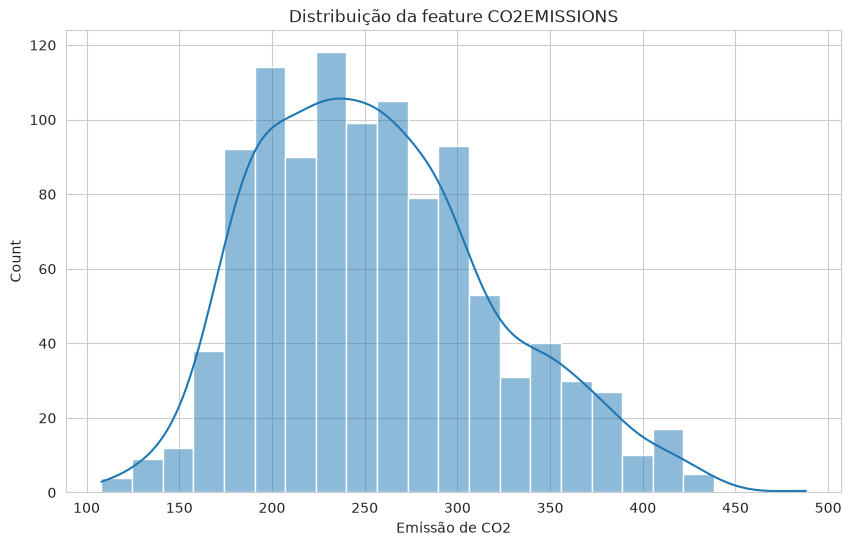

In [8]:
sns.set_style(style='whitegrid');
fig, ax = plt.subplots(figsize=(10, 6));
sns.histplot(x=df['CO2EMISSIONS'], kde=True);
ax.set_xlabel('Emissão de CO2')
plt.title('Distribuição da feature CO2EMISSIONS')

### Boxplot e possíveis outliers

O boxplot resume a distribuição usando quartis. **Q1** é o primeiro quartil (25% dos valores ficam abaixo dele), **Q2** é a mediana (50%) e **Q3** é o terceiro quartil (75%). A caixa vai de Q1 a Q3 e, portanto, contém os 50% centrais dos dados. A linha dentro da caixa marca Q2. A caixa mais comprida indica maior dispersão nessa metade central.

A diferença entre Q3 e Q1 é o **intervalo interquartil**, ou **IQR = Q3 − Q1**. No critério comum, valores abaixo de `Q1 − 1,5 × IQR` ou acima de `Q3 + 1,5 × IQR` são sinalizados como possíveis outliers. Os bigodes se estendem até os valores observados que ainda ficam dentro desses limites; pontos além deles são desenhados separadamente. A convenção dos bigodes pode variar entre ferramentas e configurações.

Um possível outlier é um sinal para investigar, não necessariamente um erro. Ele pode resultar de erro de registro, representar um caso raro e válido ou indicar que precisamos entender melhor os dados. No gráfico abaixo, cada caixa compara a distribuição de `CO2EMISSIONS` para um tipo de combustível.


Text(0.5, 1.0, 'Boxplot de relação entre o tipo do combustível e a emissão de CO²')

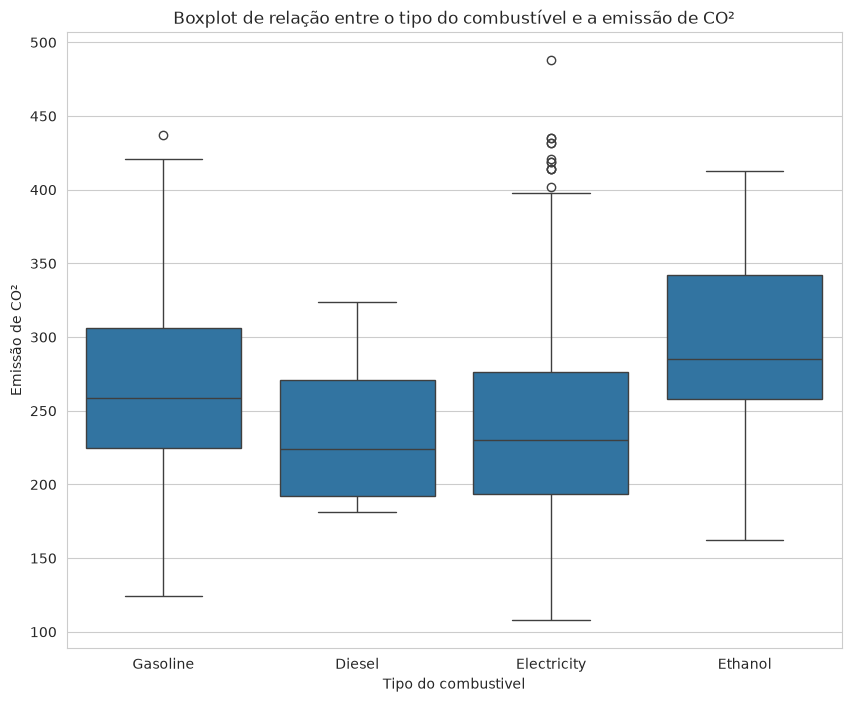

In [9]:
sns.set_style(style='whitegrid')
fig, ax = plt.subplots(figsize=(10, 8))
sns.boxplot(x=df['FUELTYPE'], y=df['CO2EMISSIONS']);
ax.set_xlabel('Tipo do combustivel')
ax.set_ylabel('Emissão de CO²')
plt.title('Boxplot de relação entre o tipo do combustível e a emissão de CO²')

### Correlação entre variáveis

O mapa de calor mostra correlações entre colunas numéricas. A correlação varia de **−1 a 1**: valores próximos de 1 indicam associação linear positiva; próximos de −1, associação linear negativa; próximos de 0, pouca associação linear. A intensidade da cor e os números ajudam a comparar os pares de variáveis.

Correlação não prova causalidade e pode não capturar relações curvas. Também é importante verificar se uma relação faz sentido no contexto e se duas variáveis carregam informação muito parecida antes de usá-las juntas em um modelo.


Text(0.5, 1.0, 'Mapa de calor com a correlação das variaveis')

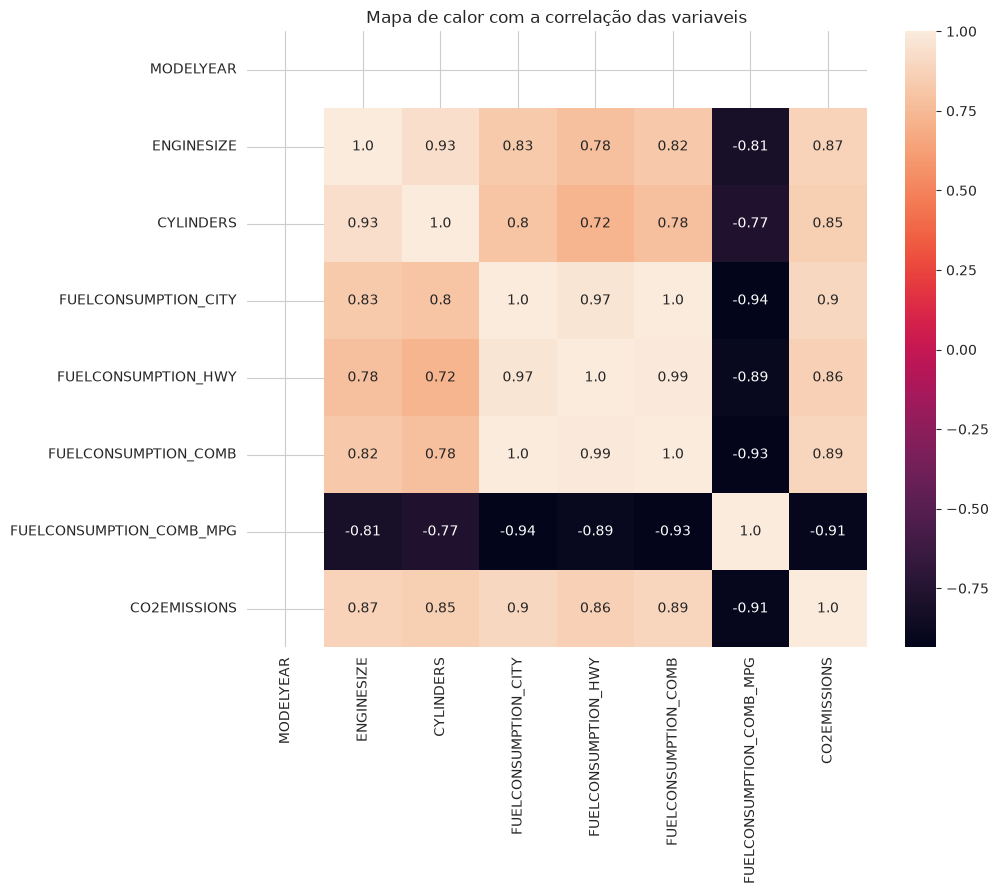

In [10]:
fig, ax = plt.subplots(figsize=(10,8))
dados_numericos = df.select_dtypes(include='number')
sns.heatmap(dados_numericos.corr(), annot=True, fmt='.2');
plt.title('Mapa de calor com a correlação das variaveis')

## Regressão Linear

A **regressão linear** é um método para estimar uma variável numérica a partir de uma ou mais variáveis de entrada. Aqui, o notebook usa características do veículo e do consumo (`x`) para estimar as emissões de CO₂ (`y`). O gráfico de dispersão abaixo mostra cada observação como um ponto; a linha de tendência ajuda a visualizar uma relação, mas não demonstra que uma variável cause a outra.

O código separa os dados em conjuntos de treino e teste: com `test_size=0.2`, 80% são usados no treino e 20% ficam para a avaliação. O modelo aprende os coeficientes usando o treino e é avaliado em dados que ficaram de fora do ajuste. `random_state=42` fixa a divisão para que ela possa ser reproduzida. Essa separação dá uma estimativa de como o modelo pode se comportar em observações novas.

As métricas impressas têm interpretações diferentes: **RMSE** (raiz do erro quadrático médio) e **MAE** (erro absoluto médio) medem o tamanho dos erros na unidade das emissões; em ambas, valores menores indicam erros menores. **R²** compara o modelo com uma referência simples baseada na média. R² não é “acurácia”: não é uma porcentagem de previsões corretas e pode até ser negativo em um conjunto de teste.


Text(0.5, 1.0, 'Relação do tamanho do motor e a emissão de CO²')

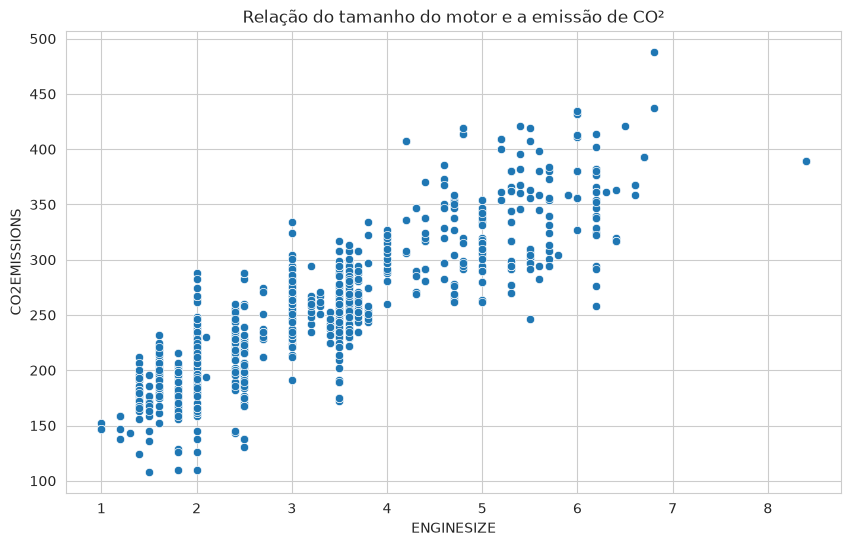

In [11]:
fig, ax = plt.subplots(figsize=(10,6))
sns.scatterplot(x=df['ENGINESIZE'], y=df['CO2EMISSIONS']);
plt.title('Relação do tamanho do motor e a emissão de CO²')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067 entries, 0 to 1066
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 1067 non-null   int64  
 1   MAKE                      1067 non-null   str    
 2   MODEL                     1067 non-null   str    
 3   VEHICLECLASS              1067 non-null   str    
 4   ENGINESIZE                1067 non-null   float64
 5   CYLINDERS                 1067 non-null   int64  
 6   TRANSMISSION              1067 non-null   str    
 7   FUELTYPE                  1067 non-null   str    
 8   FUELCONSUMPTION_CITY      1067 non-null   float64
 9   FUELCONSUMPTION_HWY       1067 non-null   float64
 10  FUELCONSUMPTION_COMB      1067 non-null   float64
 11  FUELCONSUMPTION_COMB_MPG  1067 non-null   int64  
 12  CO2EMISSIONS              1067 non-null   int64  
 13  NUMERICFUELTYPE           1067 non-null   object 
 14  FUELCLASSIFICATION 

In [13]:
from sklearn.linear_model import LinearRegression;
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
x = df[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB']]
y = df['CO2EMISSIONS']
model = LinearRegression()
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model.fit(x_train, y_train);
y_pred = model.predict(x_test)
mse = mean_squared_error(y_test, y_pred);
mae = mean_absolute_error(y_test, y_pred);
r2 = r2_score(y_test, y_pred);
print(f'RMSE: {np.sqrt(mse).round(2)} g/km')
print(f'MAE: {mae:.2f} g/km')
print(f'R² do modelo {r2:.3f}')

RMSE: 22.61 g/km
MAE: 16.69 g/km
R² do modelo: 0.876


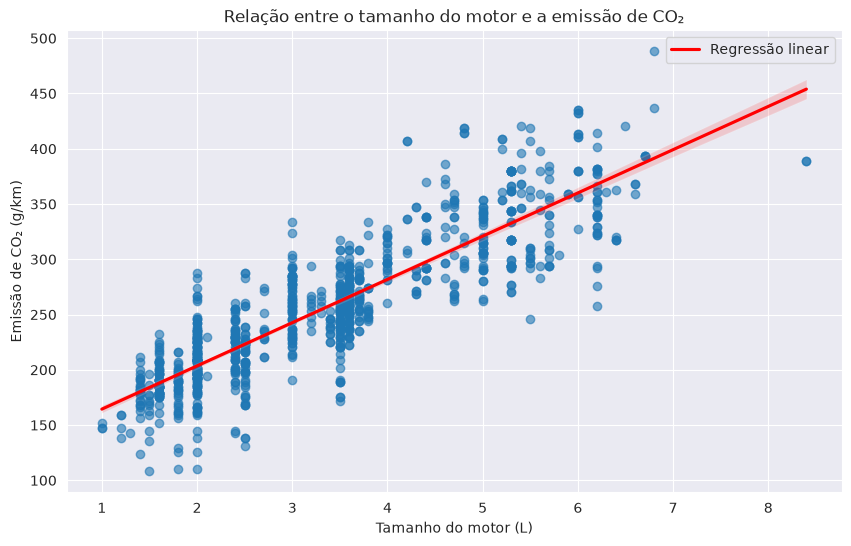

In [14]:
sns.set_style(style='darkgrid')
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(
    data=df,
    x='ENGINESIZE',
    y='CO2EMISSIONS',
    ax=ax,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red', 'label': 'Regressão linear'}
)
ax.set_title('Relação entre o tamanho do motor e a emissão de CO₂')
ax.set_xlabel('Tamanho do motor (L)')
ax.set_ylabel('Emissão de CO₂ (g/km)')
ax.legend()